In [1]:
import pickle

In [2]:
import pandas as pd
df_LP = pd.read_pickle("data/LPdata.pkl")
df_LT = pd.read_pickle("data/LTdata.pkl")
df_binance = pd.read_pickle("data/BinanceData.pkl")

df_LT = df_LT.set_index('timestamp')
df_LP = df_LP.set_index('timestamp')

In [3]:
LT_buys = df_LT[df_LT.amount0>0]
LT_sells = df_LT[df_LT.amount0<0]

In [4]:
Dtime = '10Min'

In [5]:
prices_binance = df_binance['price'].resample(Dtime).mean()
buy_activity = LT_buys['amount0'].resample(Dtime).sum()   #.rolling(10).mean()
sell_activity = LT_sells['amount0'].resample(Dtime).sum()
pool_price = df_LT['poolPricePrev'].resample(Dtime).mean()

In [6]:
LP_depth = df_LP.dropna().resample(Dtime).mean()

In [7]:
from datetime import datetime as date
d1 = date.fromisoformat('2022-01-01')
d2 = date.fromisoformat('2022-04-30')

In [8]:
def crop_dates(df, d1, d2):
    df = df[df.index >=d1]
    return df[df.index <=d2]

In [9]:
df_LP = crop_dates(df_LP, d1,d2)
LP_depth = df_LP.resample(Dtime).mean()

In [10]:
prices_binance = crop_dates(prices_binance, d1,d2)
buy_activity = crop_dates(buy_activity, d1,d2)
sell_activity = crop_dates(sell_activity, d1,d2)
pool_price = crop_dates(pool_price, d1,d2)

In [11]:
LP_depth = crop_dates(LP_depth, d1,d2)

In [12]:
LP_depth

,amount0,amount1,amountUSD,kappa
timestamp,,,,
2022-01-01 00:30:00,2403.873396,2.165605,10401.587470,9.636694e+06
2022-01-01 00:40:00,262244.736403,19.456945,-334435.772386,9.879609e+06
2022-01-01 00:50:00,NaN,NaN,NaN,NaN
2022-01-01 01:00:00,NaN,NaN,NaN,NaN
2022-01-01 01:10:00,NaN,NaN,NaN,NaN
...,...,...,...,...
2022-04-29 23:00:00,NaN,NaN,NaN,NaN
2022-04-29 23:10:00,47359.103956,52.396101,-2669.212944,1.689058e+07
2022-04-29 23:20:00,71757.201186,8.600943,-396.715378,1.744637e+07


In [13]:
df = pd.DataFrame(prices_binance).join(pd.DataFrame(sell_activity).rename(columns= {'amount0':'sells'})).join(pd.DataFrame(buy_activity).rename(columns= {'amount0':'buys'})).join(pool_price)

In [14]:
df = df.rename(columns= {'price':'Binance', 'poolPricePrev':'Uniswap'})

In [15]:
#df = df.join(LP_depth['kappa'])

In [16]:
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (15, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"
resolution_value = 300
import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')

In [17]:
df['Difference'] = df.Binance - df.Uniswap

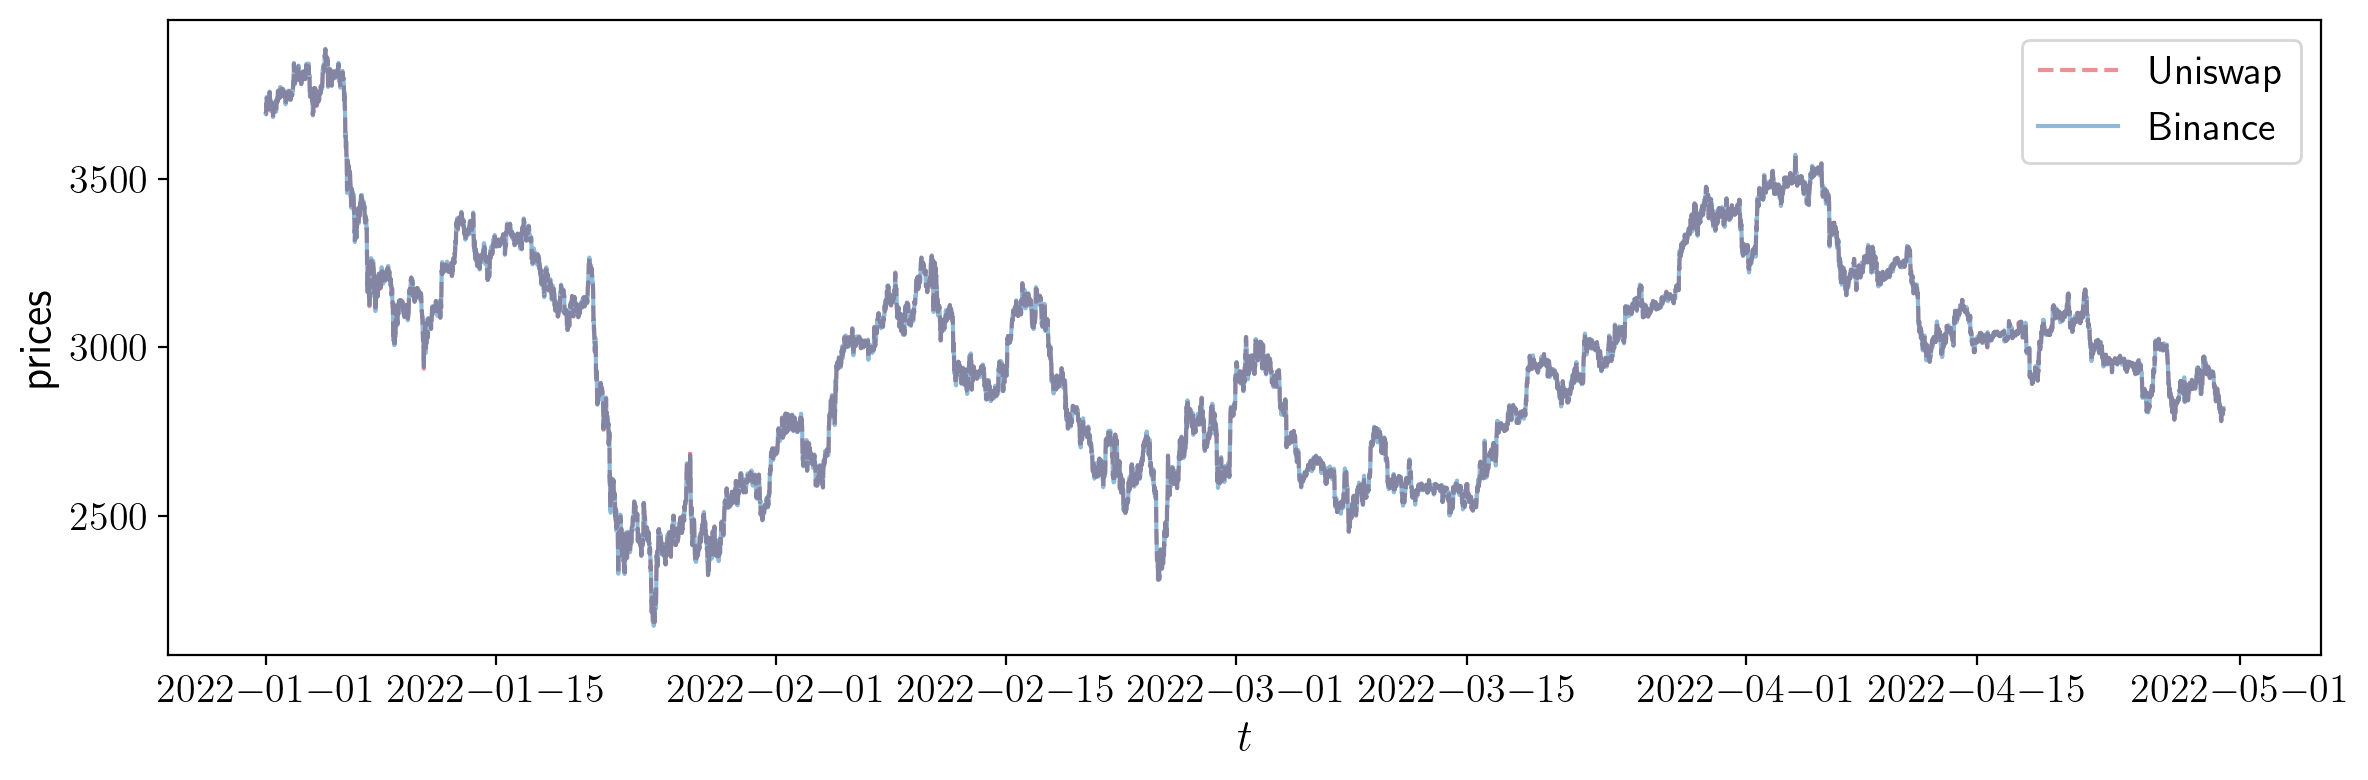

In [18]:
fig, ax = plt.subplots(1,1,figsize=(12,4))
ax.plot(df.index, df.Uniswap, color = 'tab:red', linestyle= '--', label='Uniswap', alpha = 0.5)
ax.plot(df.index, df.Binance, color = 'tab:blue', linestyle= '-', label='Binance',alpha = 0.5)
ax.set_ylabel(r'prices', fontsize = 16)
ax.set_xlabel(r'$t$', fontsize = 16)
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
import statsmodels.api as sm
import numpy as np

In [20]:
df.replace([np.inf,-np.inf], np.nan, inplace = True)

/var/folders/4m/wddbp9t11250z6q39gj69l3w0000gq/T/ipykernel_49751/1655950935.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace([np.inf,-np.inf], np.nan, inplace = True)


In [21]:
df = df.dropna()

In [22]:
mod_buys = sm.OLS(np.asarray(df.buys), sm.add_constant(np.asarray(df.Difference), prepend=False))
res_buys = mod_buys.fit()
print(res_buys.summary())

mod_sells = sm.OLS(np.asarray(-1.*df.sells), sm.add_constant(np.asarray(-1.*df.Difference), prepend=False))
res_sells = mod_sells.fit()
print(res_sells.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     633.3
Date:                Mon, 16 Dec 2024   Prob (F-statistic):          3.01e-137
Time:                        15:29:51   Log-Likelihood:            -2.7841e+05
No. Observations:               17131   AIC:                         5.568e+05
Df Residuals:                   17129   BIC:                         5.568e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1          2.322e+05   9228.876     25.165      0.0

In [23]:
#sigma = df.Binance.rolling(60*24).std().mean()
sigma = df_binance['price'].resample('1D').std().mean()
#np.round(df.Binance.dropna().rolling(6*24).std().mean()/np.sqrt(10/(24*60)),0)

In [24]:
x_buys = - res_buys.params[1]/res_buys.params[0] 
x_sells =  res_sells.params[1]/res_sells.params[0] 

In [25]:
import seaborn as sns

/Applications/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


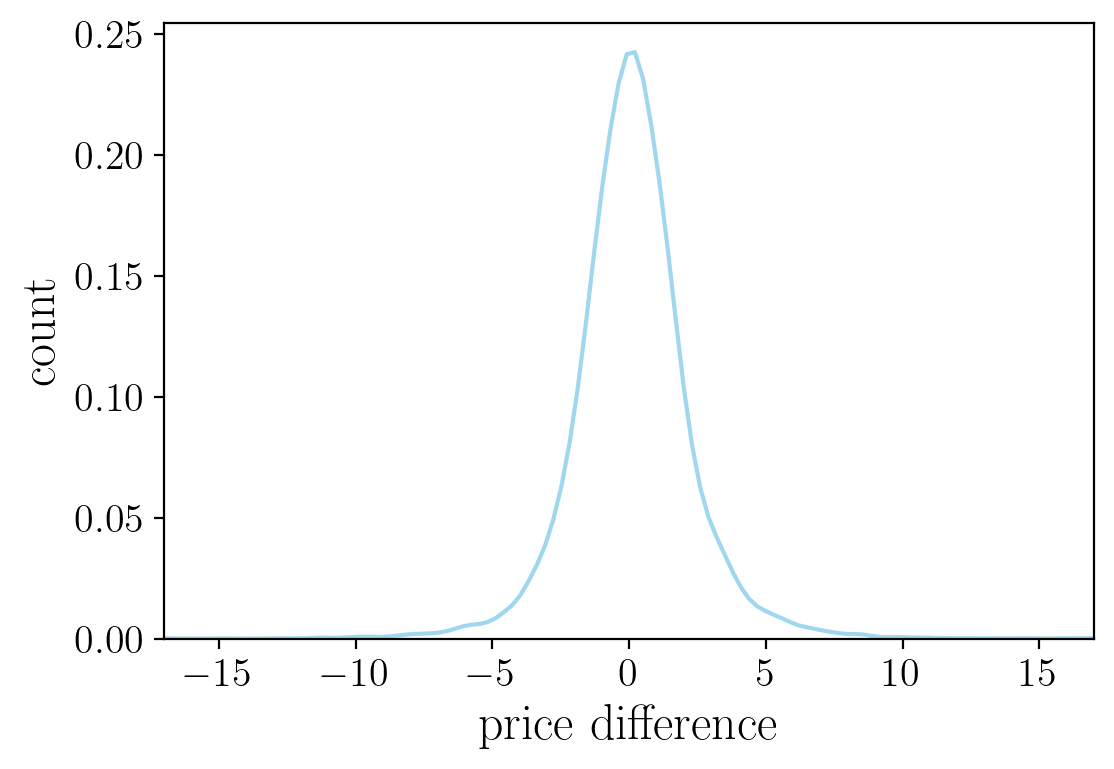

In [79]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))
sns.kdeplot(data=df.Difference, color="skyblue", label = r'$\mathrm{market}$ $\mathrm{data}$', ax=axs, alpha =0.8)
axs.set_xlabel(r'$\mathrm{price\,\,difference}$', fontsize = 18)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = 18)
plt.xlim([-17,17])
plt.show()

/Applications/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


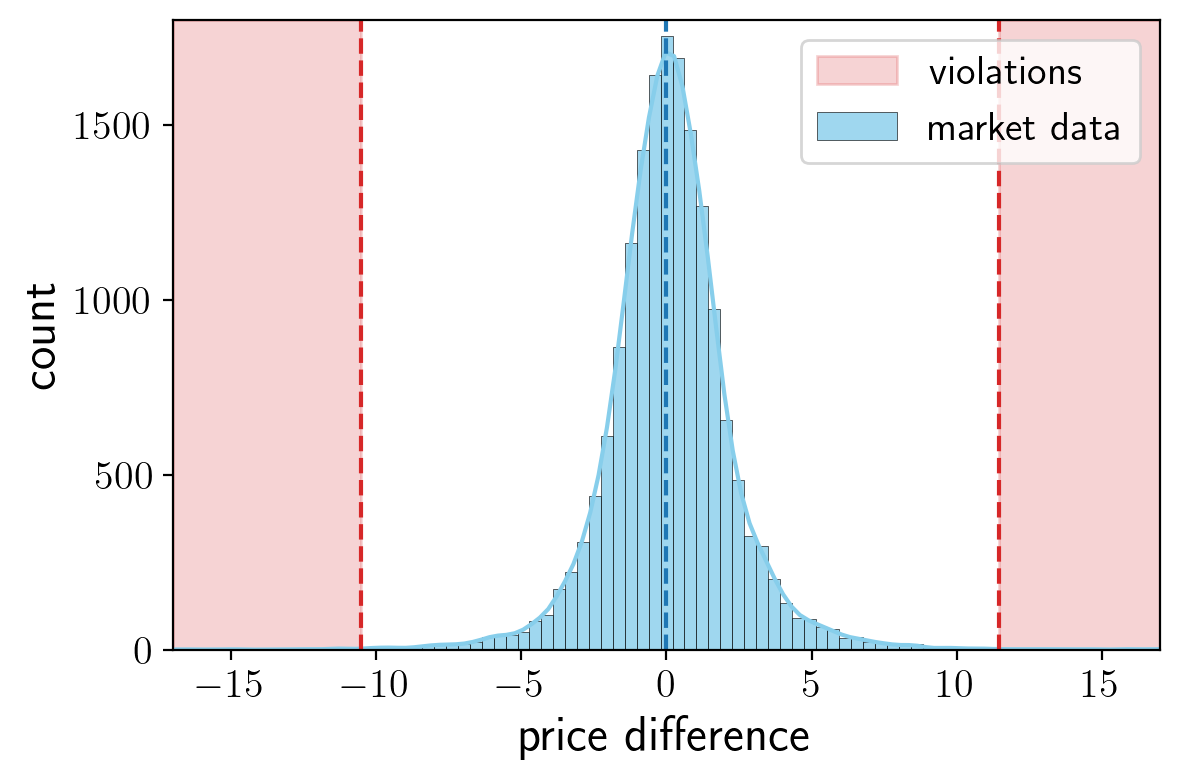

In [78]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=df.Difference, bins = 140, kde=True, color="skyblue", label = 'market data', ax=axs, alpha =0.8)
axs.set_xlabel('price difference', fontsize = 18)
axs.set_ylabel('count', fontsize = 18)

axs.axvline(0,linestyle = '--', color='tab:blue')
axs.axvline(x_buys,linestyle = '--', color='tab:red')
axs.axvline(x_sells,linestyle = '--', color='tab:red')

xmin = -17
xmax = 17
ymax = 1800

xaux_left = np.linspace(xmin, x_buys, 100)
xaux_right = np.linspace(x_sells, xmax, 100)

axs.fill_between(xaux_left, ymax*np.ones_like(xaux_left), color = 'tab:red' , alpha=0.2, label= 'violations')
axs.fill_between(xaux_right, ymax*np.ones_like(xaux_right), color = 'tab:red' , alpha=0.2)

plt.ylim([0,ymax])
plt.tight_layout()
plt.xlim([xmin,xmax])
plt.legend()

plt.tight_layout()
plt.savefig('figures/negative-intensity-regions.pdf', format="pdf", dpi=resolution_value)
plt.show()

In [80]:
x

-10.994492750981774

In [27]:
mod = sm.OLS(np.concatenate((np.asarray(df.buys), -1.*np.asarray(df.sells)), axis = 0), 
                  sm.add_constant(np.concatenate((np.asarray(df.Difference), np.asarray(-1.*df.Difference)), axis = 0), prepend=False))
res = mod.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.033
Model:                            OLS   Adj. R-squared:                  0.033
Method:                 Least Squares   F-statistic:                     1172.
Date:                Mon, 16 Dec 2024   Prob (F-statistic):          1.40e-252
Time:                        15:29:53   Log-Likelihood:            -5.5697e+05
No. Observations:               34262   AIC:                         1.114e+06
Df Residuals:                   34260   BIC:                         1.114e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1          2.242e+05   6548.785     34.234      0.0

In [55]:
x = -res.params[1]/res.params[0]

/Applications/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


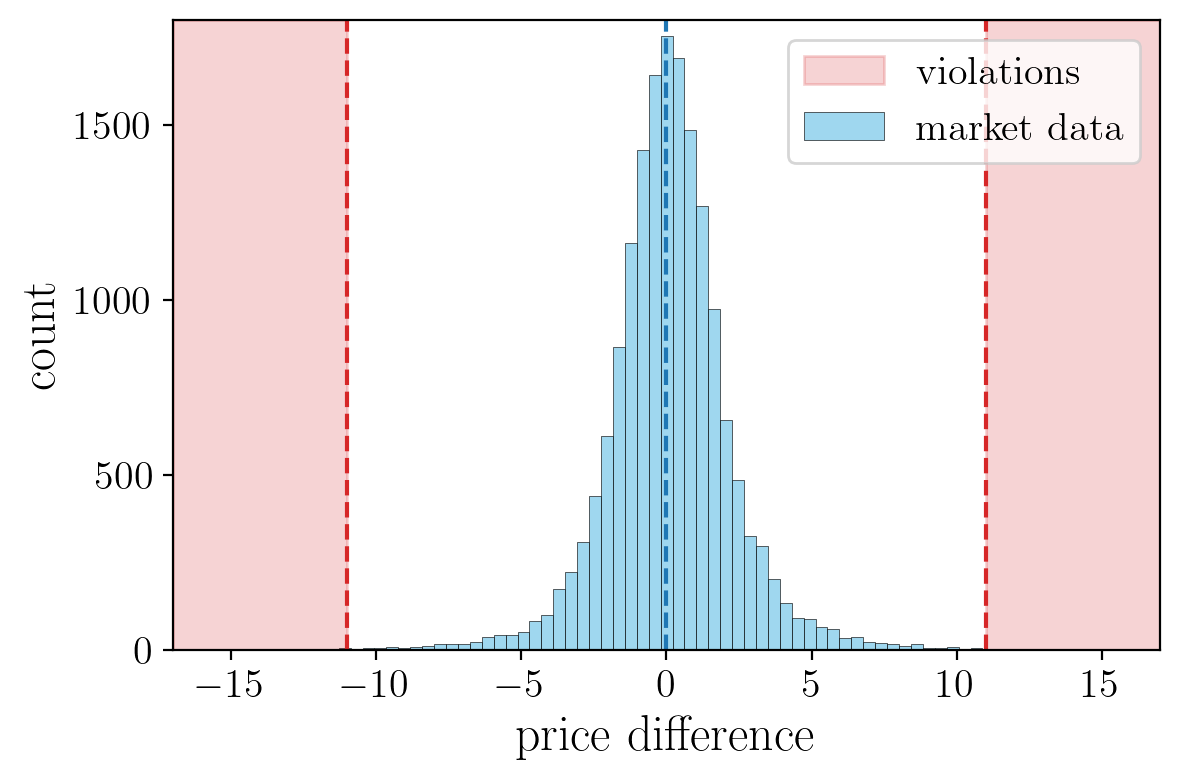

In [56]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=df.Difference, bins = 140, kde=False, color="skyblue", label = r'$\mathrm{market}$ $\mathrm{data}$', ax=axs, alpha =0.8)
axs.set_xlabel(r'$\mathrm{price\,\,difference}$', fontsize = 18)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = 18)

axs.axvline(0,linestyle = '--', color='tab:blue')
axs.axvline(x,linestyle = '--', color='tab:red')
axs.axvline(-x,linestyle = '--', color='tab:red')

xmin = -17
xmax = 17
ymax = 1800

xaux_left = np.linspace(xmin, x, 100)
xaux_right = np.linspace(-x, xmax, 100)

axs.fill_between(xaux_left, ymax*np.ones_like(xaux_left), color = 'tab:red' , alpha=0.2, label= r'$\mathrm{violations}$')
axs.fill_between(xaux_right, ymax*np.ones_like(xaux_right), color = 'tab:red' , alpha=0.2)

plt.ylim([0,ymax])
plt.tight_layout()
plt.xlim([xmin,xmax])
plt.legend()

plt.tight_layout()
plt.savefig('figures/negative-intensity-regions-symm.pdf', format="pdf", dpi=resolution_value)
plt.show()

In [57]:
(df.Difference > -x).sum()

28

In [58]:
(df.Difference < x).sum()

30

In [59]:
df.Difference.shape

(17131,)

In [60]:
64/17131

0.0037359173428287897

In [61]:
df.Binance.diff()

time
2022-01-01 00:00:00          NaN
2022-01-01 00:10:00    -0.794781
2022-01-01 00:20:00     1.578277
2022-01-01 00:30:00    13.012850
2022-01-01 00:40:00    14.678804
                         ...    
2022-04-29 23:20:00    11.076430
2022-04-29 23:30:00     5.230110
2022-04-29 23:40:00    -3.471278
2022-04-29 23:50:00     4.711611
2022-04-30 00:00:00     1.497139
Name: Binance, Length: 17131, dtype: float64

## Calibrating model parameters

In [92]:
avg_10min_buy = df['buys'].median()
avg_10min_sell = df['sells'].median()
avg_10min_trades = (avg_10min_buy - avg_10min_sell)/2

In [88]:
24*60

1440

In [91]:
(df['buys']/df['Uniswap']).median()

544.285860099574

In [53]:
avg_10min_trades

2464843.9893436907

In [62]:
res.params[0]

224188.96852913796

In [63]:
res.params[1]

2464843.9893436884

In [50]:
eta = np.round( LP_depth['amount1'].dropna().resample('1D').sum().mean(), 0)

In [51]:
eta

25589.0

In [40]:
kappaSQ = LP_depth['kappa'].iloc[-1]**2

In [81]:
avg_10min_trades

2464843.9893436907

In [94]:
xi = avg_10min_trades /df.Uniswap.iloc[-1] 

In [95]:
xi

567.5236918448079

In [72]:
a3hat = res_buys.params[0] / avg_10min_trades * 60*24/10

In [73]:
a1hat = res_buys.params[1]/ avg_10min_trades * 60*24/10

In [74]:
print(f'xi = {np.round(xi,0)}', f' a1= {np.round(a1hat,3)}', f' a3= {np.round(a3hat,3)}', f' sigma_Binance = {np.round(sigma,0)}')

xi = 875.0  a1= 142.712  a3= 13.568  sigma_Binance = 53.0


In [77]:
df.Difference.median()

0.08139180915213728